<a href="https://colab.research.google.com/github/SashaVeremchuk/ITMO-data-analytics/blob/main/1_cluster_hierarch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Дз№1 Иерархический кластерный анализ
Анализ данных на Python  
ИТМО 2026   
Веремчук Александра

## Постановка задачи
**Описание данных**
Набор данных "Леденцы" содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:   
* V1: Я потребляю леденцы, чтобы освежить дыхание  
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее  
* V3: Я потребляю леденцы, чтобы освежить полость рта   
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту  
* V5: Я потребляю леденцы как заменитель других кондитерских изделий  
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого  
* V7: Леденцы помогают мне сконцентрироваться  
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать  
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле  
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа  
* V11: Я потребляю леденцы для улучшения самочувствия  

**Задача**  
1. Определить число кластеров и обосновать выбор;   
2. Выполнить кластеризацию;  
3. Предложить содержательную интерпретацию полученных групп.



## Подключение библиотек

In [61]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
# используем команду linkage для иерар. кластерного анализа
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [62]:
# загрузка данных
df = pd.read_csv("data/lollipops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


## Проведение иерархического клстерного анализа

### Кластеризация
Для проведения иерархического кластерного анализа  <br>
используем команду `linkage` из библиотеки scipy. В ней задаём 2 гиперпараметра:
  * `method` - способ вычисления расстояний между кластерами;
  * `metric` - способ вычисления расстояний между точками.

`method` = 'ward'. Метод Уорда пытается минимизировать общую внутрикластерную дисперсию, также известную как сумма квадратов внутри кластеров, на каждом шаге иерархии. Он берёт центр будущего кластера и считает, насколько далеко все точки группы от него разбросаны. Нужно, чтобы сумма квадратов расстояний точек внутри каждого кластера до среднего значения кластера была минимальной.   
Выбрали его, потому что метод Уорда создавался специально для социально-экономических задач и маркетинга. Его цель - найти плотные, округлые, изолированные друг от друга «облака» данных. В задаче с леденцами мы как раз решаем задачу по нахождению групп потребителей.   
`metric` = 'euclidean'. Использем этот способ, потому что у нас в данных единая сбалансированная шкала и Евклидово расстояние яаляется стандартом.


In [63]:
link = linkage(df, method='ward', metric='euclidean')

В объекте ```link```  хранится история объединения кластеров. Это матрица numpy ```(n-1) x 4```, где ```n``` - число наблюдений. Каждая строка матрицы описывает слияние очередной пары кластеров с номерами ```link[i, 0]``` и ```link[i, 1]```. Новому кластеру присваивается номер ```n + i```. Столбец ```link[i, 2]``` содержит расстояние между объединяемыми кластерами, а ```link[i, 3]``` - объём нового кластера.

In [64]:
link[:5]

array([[  0.,   4.,   0.,   2.],
       [  1.,   3.,   0.,   2.],
       [  2.,   6.,   0.,   2.],
       [  5., 339.,   0.,   3.],
       [ 32., 338.,   0.,   3.]])

### Построение дендограммы

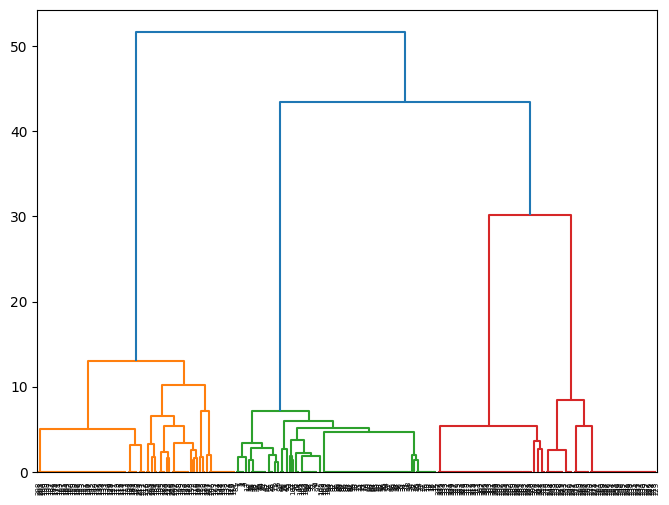

In [65]:
fig = plt.figure(figsize=(8,6))
dn = dendrogram(link, labels= df.index.tolist())

Алгоритм подкрасил 3 кластера в дендограмме. Но видно, что в красном кластере, расстояние между двумя последними кластерами слишком велико, поэтому, я бы выделила 4 кластера. Это так же подтвержается анализом вопросов, где можно выделить 4 группы применения леденцов:
  * Для свежести дыхания;
  * Для концентрации;
  * Как сладкое;
  * Для ослабления симптомов болезни.  
  
Я предположу, что свежесть дыхания влияет на концентрацию, поэтому эти группы респондентов схожи.

### Разбиение на группы

Добавим к таблице данных df столбец ```cluster```, содержащий код того кластера, в который попал объект. Это сделаем с помощью команды ```fcluster```. <br>
Первый аргумент команды это объект ```link```, содержащий результаты кластеризации.  <br>
Третий аргумент ```criterion``` указывает, как разбивать на кластеры (```distance```, если остановка объединений по расстоянию между кластерами или ```maxclust```, если будет заданно число кластеров).  <br>
Вторым  аргументом является либо пороговое значение для расстояния между кластерами, либо количество кластеров, в зависимости от значения аргумента ```criterion```.

In [66]:
# Выделяем 4 кластера
df['cluster'] = fcluster(link, 4, criterion='maxclust')

In [67]:
# Чтобы интерпретировать группы считаем средний балл по каждому из 11 вопросов для каждого кластера
cluster_profiles = df.groupby('cluster').mean().round(2).T
cluster_profiles

cluster,1,2,3,4
V1,2.82,4.85,3.00,3.00
V2,2.83,4.80,2.97,3.00
V3,2.77,4.84,2.97,3.00
V4,2.62,4.68,2.92,3.00
V5,2.61,3.04,2.92,4.85
V6,2.58,3.04,2.95,4.85
V7,2.75,3.00,4.92,3.00
V8,2.92,2.99,4.92,2.92
V9,4.95,3.07,3.00,2.75
V10,4.81,3.05,3.00,2.75


Видно, что собираются 4 группы, где у вопросов ср. балл > 4:
  1) Медицинские: V9, V10, V11;
  2) Освежающие: V1, V2, V3, V4;
  3) Для концентрации: V7, V8;
  4) Сладкоежки: V5, V6.



In [68]:
# Смотрим сколько наблюдений попало в каждый кластер
df.groupby('cluster').size()

,0
cluster,
1,108
2,110
3,59
4,61


## Вывод
1) Медецинские. 108 человек используют леденцы в медецинских целях, для ослабления симптомов болезни;
2) Освежающие. 110 человек используют леденцы для освежения дыхания.
3) Для концентрации. 59 человек используют леденцы для концентрации.
4) Сладкоежки. 61 человек используют леденцы как замену сладкого.

При производстве леденцов стоит обращать внимание на потребителей этих групп, особенно на группы "Медецинские" и "Освежающие", тк большинство респондентов причисляют себя к этой группе.